# Multivariate Linear Regression

In [23]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, MinMaxScaler, RobustScaler
import statsmodels.api as sm
from sklearn.metrics import r2_score, mean_squared_error
from math import sqrt

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

font = {'size': 16}
matplotlib.rc('font', **font)
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Verdana"]

## Data and Model Import

In [2]:
# Mapping dictionary
mapping_dict = {'Arid': 0, 'Snow': 1, 'Temperate': 2, 'Tropical': 3}

In [3]:
# SUE dataset
data_sue                 = pd.read_csv('data/data_sue.csv')
data_sue['Coastal?']     = data_sue['Coastal?'].fillna(False).astype(int)
data_sue['Climate Zone'] = data_sue['Climate Zone'].map(mapping_dict)

In [4]:
# NTL dataset
data_ntl                 = pd.read_csv('data/data_ntl.csv')
data_ntl['Coastal?']     = data_ntl['Coastal?'].astype(int)
data_ntl['Climate Zone'] = data_ntl['Climate Zone'].map(mapping_dict)

In [5]:
features = ['BSA', 'NDBI', 'NDVI', 'DEM', 'Coastal?', 'Climate Zone']
label    = 'SUHI'

## Helper Functions

In [6]:
def get_data(dataset):
    Xy = dataset[features+[label]].dropna().copy()
    X  = Xy.copy()[features]
    y  = Xy.copy()[label]

    return X, y

### Feature Importance
We provide feature importance of the linear regression coefficients by standardizing the features.

In [7]:
def standard_transform(X):
    X_transform = X.copy()
    for feature in features:
        X_transform[feature] = StandardScaler().fit_transform(np.array(X_transform[feature]).reshape(-1, 1))
        return X_transform

In [8]:
def robust_transform(X):
    X_transform = X.copy()
    for feature in features:
        X_transform[feature] = RobustScaler().fit_transform(np.array(X_transform[feature]).reshape(-1, 1))
        return X_transform

In [9]:
def minmax_transform(X):
    X_transform = X.copy()
    for feature in features:
        X_transform[feature] = MinMaxScaler().fit_transform(np.array(X_transform[feature]).reshape(-1, 1))
        return X_transform

In [10]:
def get_model(X, y):
    X       = sm.add_constant(X)
    model   = sm.OLS(y, np.asarray(X))
    results = model.fit()
    
    return model, results

In [11]:
def save_results(results, filename):
    summary = pd.DataFrame({'Features': ['Constant']+features, 'Coefficients': np.asarray(results.params), 
                           'LB': np.asarray(results.conf_int()[0]), 'UB': np.asarray(results.conf_int()[1]), 
                           'pval': np.asarray(results.pvalues)})
    summary = summary.round(4)
    summary.to_csv('tables/linear_regression/{}.csv'.format(filename),index=False)
    return

In [12]:
def weighted_effect(X_tranform, feat_imp):
    weighted_X = X_tranform.copy()
    weights    = feat_imp['Coefficients'].to_numpy()
    for i in range(len(features)):
        feature = features[i]
        weight  = weights[i] 
        weighted_X[feature] = weighted_X[feature] * weight
    return weighted_X

In [24]:
def plot_ols_imp(transform='standard'):
    feature_names = ['\u0394BSA', '\u0394NDBI', '\u0394NDVI', '\u0394DEM', 'Coastal?', 'Climate Zone']
    
    nrows,ncols=2,2
    fig, ax = plt.subplots(nrows, ncols, figsize=(10,10), constrained_layout=True, sharex='col')
    datasets = [data_sue, data_ntl]

    for i in range(nrows):
        X, y = get_data(datasets[i]) # get data
        if transform == 'standard':
            X = standard_transform(X) # transform data
        if transform == 'robust':
            X = robust_transform(X) # transform data
        if transform == 'minmax':
            X = minmax_transform(X) # transform data
        model, results = get_model(X, y) # get model
        #print(results.summary())
        results_df = pd.DataFrame({
            "var": ['Constant'] + features,  
            "coef": results.params,
            "pvals": results.pvalues,
            "conf_lower": results.conf_int()[0],
            "conf_higher": results.conf_int()[1]
        }).round(2)
        display(results_df)
        
        feat_imp = pd.DataFrame({'Features': features, 'Feature Names':feature_names, 'Coefficients': np.asarray(results.params[1:]), 
                                 'LB': np.asarray(results.conf_int()[0][1:]), 'UB': np.asarray(results.conf_int()[1][1:])})
        weighted_X = weighted_effect(X, feat_imp)
        feat_imp_sorted = feat_imp.sort_values(by='Coefficients', key=abs, ascending=True)

        # Uneven confidence intervals (errors)
        lower_errors = feat_imp_sorted['LB'].to_numpy()
        upper_errors = feat_imp_sorted['UB'].to_numpy()

        # Asymmetric error values for plotting
        errors = [np.abs(lower_errors), np.abs(upper_errors)]

        # Create the plot with error bars
        ax[i][0].errorbar(np.asarray(feat_imp_sorted['Coefficients']), np.asarray(feat_imp_sorted['Feature Names']), xerr=errors, fmt='o', capsize=5)
        ax[i][0].set_xlabel('Standarized Weights')
        ax[i][0].axvline(0, linestyle='dashed')
        ax[i][0].grid(True)
        method = 'SUE' if i == 0 else 'NTL'
        ax[i][0].set_title(str(i+1) + '(a) ' + method, fontsize=14)

        ax[i][1].boxplot([weighted_X[feature].to_numpy() for feature in feat_imp_sorted['Features'].to_list()], vert=False)
        ax[i][1].axvline(0, linestyle='dashdot')
        ax[i][1].set_xlabel('Effect on SUHI')
        ax[i][1].tick_params(labelleft=False) 
        ax[i][1].grid(True)
        ax[i][1].set_title(str(i+1) + '(b) ' + method, fontsize=14) #+ dataset, fontsize=14)

    plt.savefig('graphs/feature_importance/linear_feature_importance_{}.jpg'.format(transform), bbox_inches='tight', dpi=1000)


## SUE OLS Model Results

In [14]:
X, y = get_data(data_sue)
model, results = get_model(X, y)
y_pred = model.predict(results.params, sm.add_constant(X))
save_results(results, 'SUE')
print(label)
print('R2: {:.3f}'.format(results.rsquared))
print('RMSE: {:.3f}'.format(sqrt(results.mse_total)))
print('MBE: {:.3f}'.format(np.mean(y_pred - y)))

SUHI
R2: 0.558
RMSE: 3.058
MBE: -0.000


## NTL OLS Model Results

In [15]:
X, y = get_data(data_ntl)
model, results = get_model(X, y)
y_pred = model.predict(results.params, sm.add_constant(X))
save_results(results, 'NTL')
print(label)
print('R2: {:.3f}'.format(results.rsquared))
print('RMSE: {:.3f}'.format(sqrt(results.mse_total)))
print('MBE: {:.3f}'.format(np.mean(y_pred - y)))

SUHI
R2: 0.535
RMSE: 3.894
MBE: -0.000


In [16]:
features = ['BSA', 'NDBI', 'NDVI', 'DEM', 'Coastal?', 'Climate Zone']

## OLS Feature Importance

,var,coef,pvals,conf_lower,conf_higher
const,Constant,1.36,0.0,1.31,1.41
x1,BSA,0.59,0.0,0.57,0.61
x2,NDBI,8.58,0.0,8.21,8.94
x3,NDVI,-13.81,0.0,-14.05,-13.56
x4,DEM,-0.00,0.0,-0.00,-0.00
x5,Coastal?,-2.61,0.0,-2.70,-2.51
x6,Climate Zone,-0.10,0.0,-0.13,-0.07


,var,coef,pvals,conf_lower,conf_higher
const,Constant,1.38,0.0,1.31,1.45
x1,BSA,0.55,0.0,0.53,0.58
x2,NDBI,15.20,0.0,14.79,15.61
x3,NDVI,-6.44,0.0,-6.85,-6.03
x4,DEM,-0.00,0.0,-0.01,-0.00
x5,Coastal?,-0.43,0.0,-0.49,-0.38
x6,Climate Zone,0.60,0.0,0.56,0.64


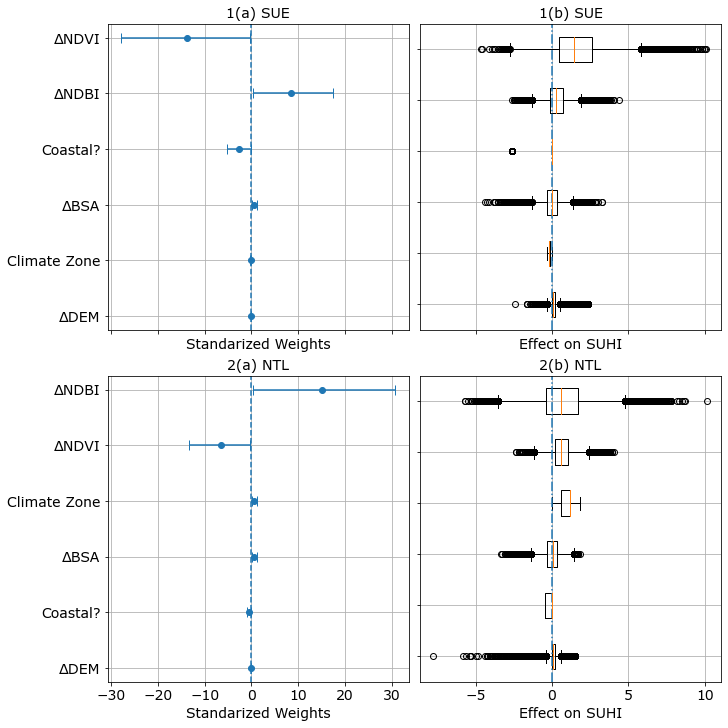

In [25]:
font = {'size': 14}
matplotlib.rc('font', **font)
plot_ols_imp(transform='standard')

                            OLS Regression Results                            
Dep. Variable:                   SUHI   R-squared:                       0.558
Model:                            OLS   Adj. R-squared:                  0.558
Method:                 Least Squares   F-statistic:                 1.085e+04
Date:                Wed, 22 Oct 2025   Prob (F-statistic):               0.00
Time:                        15:44:21   Log-Likelihood:            -1.0969e+05
No. Observations:               51540   AIC:                         2.194e+05
Df Residuals:                   51533   BIC:                         2.195e+05
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.3709      0.027     51.296      0.0

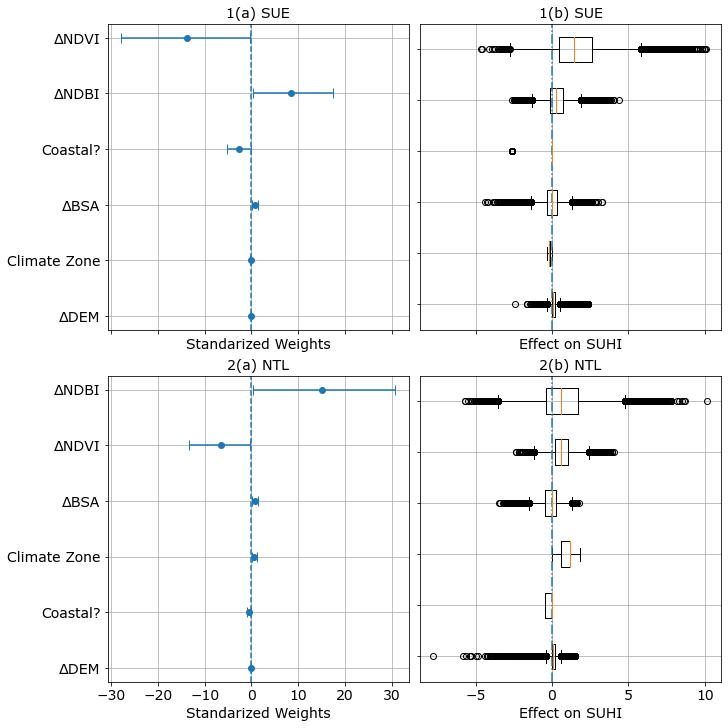

In [21]:
plot_ols_imp(transform='robust')

                            OLS Regression Results                            
Dep. Variable:                   SUHI   R-squared:                       0.558
Model:                            OLS   Adj. R-squared:                  0.558
Method:                 Least Squares   F-statistic:                 1.085e+04
Date:                Wed, 22 Oct 2025   Prob (F-statistic):               0.00
Time:                        15:44:26   Log-Likelihood:            -1.0969e+05
No. Observations:               51540   AIC:                         2.194e+05
Df Residuals:                   51533   BIC:                         2.195e+05
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -3.0093      0.080    -37.683      0.0

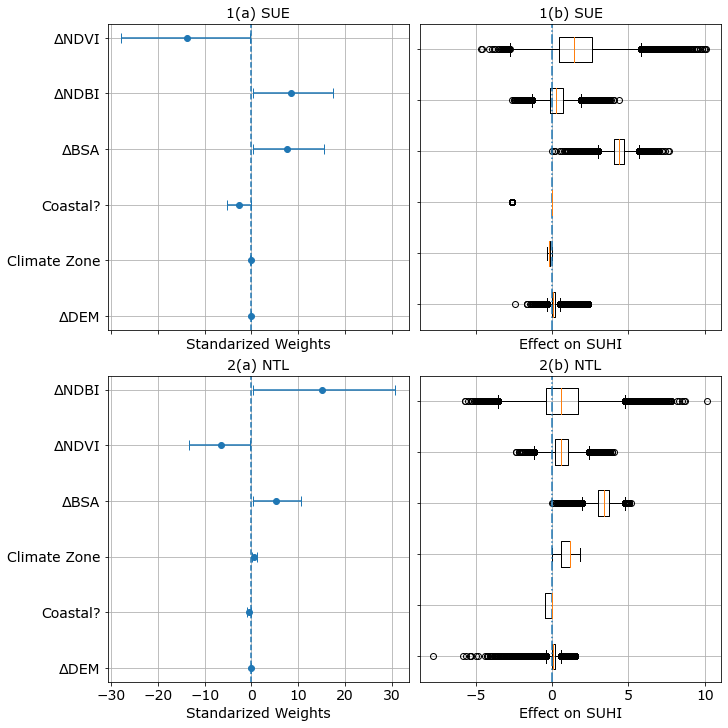

In [22]:
plot_ols_imp(transform='minmax')